In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/results.csv")
print(df.shape)
df.head()

(4320, 12)


,season,round,race_name,circuit,date,driver,constructor,grid,finish_position,status,points,quali_position
0,2016,1,Australian Grand Prix,albert_park,2016-03-20,rosberg,mercedes,2,1,Finished,25.0,2.0
1,2016,1,Australian Grand Prix,albert_park,2016-03-20,hamilton,mercedes,1,2,Finished,18.0,1.0
2,2016,1,Australian Grand Prix,albert_park,2016-03-20,vettel,ferrari,3,3,Finished,15.0,3.0
3,2016,1,Australian Grand Prix,albert_park,2016-03-20,ricciardo,red_bull,8,4,Finished,12.0,8.0
4,2016,1,Australian Grand Prix,albert_park,2016-03-20,massa,williams,6,5,Finished,10.0,6.0


In [2]:
df["podium"] = (df["finish_position"] <= 3).astype(int)

print("Total entries:", len(df))
print("Podium entries:", df["podium"].sum())
print("Podium rate:", round(df["podium"].mean() * 100, 1), "%")

Total entries: 4320
Podium entries: 642
Podium rate: 14.9 %


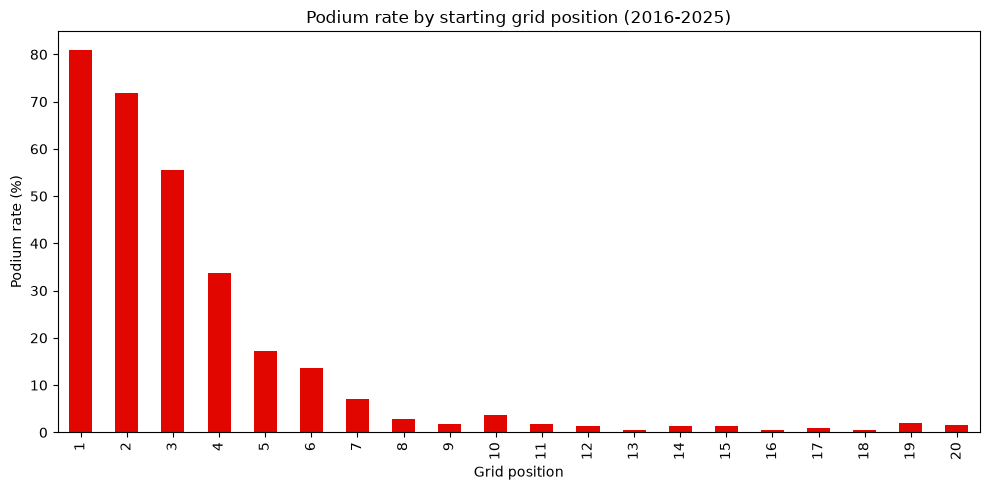

In [3]:
import matplotlib.pyplot as plt

rate_by_grid = df[df["grid"].between(1, 20)].groupby("grid")["podium"].mean() * 100

plt.figure(figsize=(10, 5))
rate_by_grid.plot(kind="bar", color="#e10600")
plt.title("Podium rate by starting grid position (2016-2025)")
plt.xlabel("Grid position")
plt.ylabel("Podium rate (%)")
plt.tight_layout()
plt.savefig("../reports/figures/podium_by_grid.png", dpi=150)
plt.show()

In [4]:
df["status"].value_counts().head(10)

status
Finished            2362
+1 Lap               806
Lapped               297
Retired              171
+2 Laps              145
Collision            104
Engine                54
Accident              54
Collision damage      43
Brakes                34
Name: count, dtype: int64

In [5]:
df["finished"] = df["status"].str.contains("Finished|\\+\\d+ Lap", regex=True).astype(int)
df["dnf"] = 1 - df["finished"]

print("DNF rate:", round(df["dnf"].mean() * 100, 1), "%")
df.groupby("constructor")["podium"].mean().sort_values(ascending=False).head(8) * 100

DNF rate: 22.9 %


constructor
mercedes        50.233645
red_bull        41.588785
ferrari         32.710280
mclaren         17.056075
racing_point     5.263158
aston_martin     3.964758
alpine           2.631579
force_india      2.419355
Name: podium, dtype: float64